# 07 — KL-NMF (05) vs Wasserstein NMF: mirror descent (06) and the dual solver of Rolet et al. (06a)

All methods were fitted on the same 9 simulated catalogues from `02a` with K = true number of signatures. This notebook loads their saved solutions and scores them **with the same code**:

| aspect | metrics |
|---|---|
| signatures | matched cosine (Hungarian), number recovered (cosine ≥ 0.9), worst match |
| signatures, transport view | entropic OT distance between true and estimated signature under each ground cost |
| exposures | correlation with the true exposures, relative absolute error, and how both depend on sample burden |
| fit to the data | per-sample cosine between $x_j$ and its reconstruction |

Per-signature differences are tested with a paired Wilcoxon signed-rank test.

> **Caveat on the OT metrics.** A W-NMF trained with cost $C$ is directly optimised for transport distances under $C$, so it has a built-in advantage when scored with that same cost. The cosine and exposure metrics are neutral between the two methods; the OT scores are reported under *every* cost, including ones a method was not trained with.

**Methods:** `KL-NMF` (05); `W-NMF (<cost>)`, alternating mirror descent on the entropic OT loss (06); `W-NMF dual (<cost>)`, block-coordinate descent on the Fenchel duals of Rolet, Cuturi & Peyré 2016 (06a). Any method whose results folder is missing is skipped.

**Inputs:** `simulated_data/` (02a), `results/klnmf/` (05), `results/wnmf/<cost>/` (06), `results/wnmf_dual/<cost>/` (06a), `data/cost_matrix/` (03, 04).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from scipy.stats import wilcoxon

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
SIM = next((p for p in [ROOT / "simulated_data", DATA / "simulated_data"] if p.is_dir()), None)
assert SIM is not None, "simulated_data/ not found: run 02a first"
RES = ROOT / "results"

SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SUB_COLORS = dict(zip(SUBS, ["#1ebff0", "#050708", "#e62725", "#cbcacb", "#a1cf64", "#edc8c5"]))
BASES = ["A", "C", "G", "T"]
CHANNELS = pd.Index([f"{f}[{s}]{t}" for s in SUBS for f in BASES for t in BASES], name="MutationType")
SUB_OF = CHANNELS.str[2:5].to_numpy(dtype=str)

N_SIGNATURES_LIST = [8, 15, 25]
NOISE_LEVELS = [0.02, 0.04, 0.06]
DETAIL = (15, 0.04)
COS_GOOD = 0.9
EPS_EVAL = 0.01          # entropic regularisation for the OT scores (cost scaled to max 1)

METHODS = {"KL-NMF": RES / "klnmf"}
for folder, label in [("wnmf", "W-NMF"), ("wnmf_dual", "W-NMF dual")]:
    if (RES / folder).is_dir():
        METHODS.update({f"{label} ({p.name})": p for p in sorted((RES / folder).iterdir()) if p.is_dir()})
assert len(METHODS) > 1, "need results from both 05 and 06"
COSTS = {p.stem.removeprefix("C_").removesuffix("_scaled"): pd.read_csv(p, index_col=0).loc[CHANNELS, CHANNELS].values
         for p in sorted((DATA / "cost_matrix").glob("C_*_scaled.csv")) if not p.stem.startswith("C_linear")}
METHOD_COLORS = dict(zip(METHODS, ["#7f7f7f", "#2a78d6", "#eb6834", "#1baf7a", "#9467bd", "#d62728", "#8c564b"]))
print("methods:", list(METHODS)); print("OT scoring costs:", list(COSTS))

methods: ['KL-NMF', 'W-NMF (graph_struct)', 'W-NMF (lin_hamming)', 'W-NMF dual (graph_struct)', 'W-NMF dual (lin_hamming)']
OT scoring costs: ['graph_data', 'graph_energy', 'graph_struct', 'lin_hamming', 'lin_tstv']


## 1. Load everything and score it

In [2]:
def tag(k, noise):
    return f"k{k}_noise{int(round(noise * 100))}pct"


def cosine_matrix(A, B):
    A = A / np.linalg.norm(A, axis=0, keepdims=True)
    B = B / np.linalg.norm(B, axis=0, keepdims=True)
    return A.T @ B


def ot_columns(A, B, C, eps=EPS_EVAL, n_iter=2000):
    # entropic OT cost <T, C> between matching columns of A and B (batched Sinkhorn)
    A = (A + 1e-12) / (A + 1e-12).sum(0); B = (B + 1e-12) / (B + 1e-12).sum(0)
    K = np.exp(-C / eps); v = np.ones_like(B)
    for _ in range(n_iter):
        u = A / (K @ v); v = B / (K.T @ u)
    return np.sum(u * ((K * C) @ v), 0)


sig_rows, sample_rows = [], []
for k in N_SIGNATURES_LIST:
    for noise in NOISE_LEVELS:
        t = tag(k, noise)
        X = pd.read_csv(SIM / f"X_{t}.csv", index_col=0).loc[CHANNELS]
        Wt = pd.read_csv(SIM / f"W_true_{t}.csv", index_col=0).loc[CHANNELS]
        Ht = pd.read_csv(SIM / f"H_true_{t}.csv", index_col=0)
        burden = X.sum().values
        for meth, d in METHODS.items():
            if not (d / f"W_{t}.csv").exists():
                continue
            We = pd.read_csv(d / f"W_{t}.csv", index_col=0).loc[CHANNELS]
            He = pd.read_csv(d / f"H_{t}.csv", index_col=0)
            # re-match here so both methods are matched with identical code
            S = cosine_matrix(Wt.values, We.values)
            r, c = linear_sum_assignment(-S)
            We = We.iloc[:, c].set_axis(Wt.columns[r], axis=1); He = He.iloc[c].set_axis(Wt.columns[r], axis=0)
            We, He = We[Wt.columns], He.loc[Wt.columns]
            cos = np.diag(cosine_matrix(Wt.values, We.values))
            ot = {f"OT[{cn}]": ot_columns(Wt.values, We.values, Cm) for cn, Cm in COSTS.items()}
            for i, s in enumerate(Wt.columns):
                sig_rows.append(dict(method=meth, k=k, noise=noise, signature=s, cosine=cos[i],
                                     exposure_r=np.corrcoef(He.loc[s], Ht.loc[s])[0, 1],
                                     exposure_rel_err=np.abs(He.loc[s] - Ht.loc[s]).sum() / Ht.loc[s].sum(),
                                     **{n: v[i] for n, v in ot.items()}))
            R = We.values @ He.values
            rec_cos = np.diag(cosine_matrix(X.values.astype(float), R))
            exp_err = np.abs(He.values - Ht.values).sum(0) / burden
            for j in range(X.shape[1]):
                sample_rows.append(dict(method=meth, k=k, noise=noise, burden=burden[j], recon_cosine=rec_cos[j], exposure_err=exp_err[j]))

sig = pd.DataFrame(sig_rows)
samp = pd.DataFrame(sample_rows)
print(sig.shape, samp.shape)

(720, 12) (9000, 6)


## 2. Summary

In [3]:
OT_COLS = [c for c in sig.columns if c.startswith("OT[")]
summary = (sig.groupby(["k", "noise", "method"])
           .agg(mean_cos=("cosine", "mean"), min_cos=("cosine", "min"),
                recovered=("cosine", lambda x: f"{(x >= COS_GOOD).sum()}/{len(x)}"),
                exposure_r=("exposure_r", "mean"), exposure_rel_err=("exposure_rel_err", "mean"),
                **{c: (c, "mean") for c in OT_COLS}))
summary.round(3)

mean_cos  min_cos recovered  exposure_r  exposure_rel_err  OT[graph_data]  OT[graph_energy]  OT[graph_struct]  \
k  noise method                                                                                                                                     
8  0.02  KL-NMF                        0.992    0.958       8/8       0.991             0.217           0.029             0.027             0.031   
         W-NMF (graph_struct)          0.992    0.953       8/8       0.989             0.248           0.032             0.029             0.033   
         W-NMF (lin_hamming)           0.993    0.966       8/8       0.993             0.228           0.031             0.028             0.032   
         W-NMF dual (graph_struct)     0.976    0.912       8/8       0.981             0.386           0.056             0.052             0.058   
         W-NMF dual (lin_hamming)      0.986    0.937       8/8       0.988             0.298           0.040             0.036             0.041   
   0.04  KL-NMF                        0.990    0.939       8/8       0.988             0.217           0.027             0.025             0.028   
         W-NMF (graph_struct)          0.991    0.950       8/8       0.991             0.245           0.033             0.030             0.034   
         W-NMF (lin_hamming)           0.992    0.957       8/8       0.992             0.223           0.029             0.026             0.030   
         W-NMF dual (graph_struct)     0.963    0.806       7/8       0.977             0.418           0.060             0.055             0.062   
         W-NMF dual (lin_hamming)      0.976    0.875       7/8       0.986             0.338           0.044             0.040             0.045   
   0.06  KL-NMF                        0.990    0.945       8/8       0.991             0.225           0.029             0.027             0.030   
         W-NMF (graph_struct)          0.990    0.943       8/8       0.989             0.265           0.035             0.033             0.037   
         W-NMF (lin_hamming)           0.991    0.950       8/8       0.992             0.231           0.028             0.026             0.029   
         W-NMF dual (graph_struct)     0.971    0.880       7/8       0.980             0.405           0.060             0.055             0.061   
         W-NMF dual (lin_hamming)      0.980    0.894       7/8       0.989             0.321           0.043             0.039             0.045   
15 0.02  KL-NMF                        0.969    0.715     14/15       0.971             0.307           0.047             0.046             0.049   
         W-NMF (graph_struct)          0.928    0.379     12/15       0.917             0.439           0.061             0.059             0.063   
         W-NMF (lin_hamming)           0.974    0.828     13/15       0.972             0.322           0.045             0.045             0.047   
         W-NMF dual (graph_struct)     0.950    0.831     12/15       0.954             0.505           0.068             0.070             0.071   
         W-NMF dual (lin_hamming)      0.926    0.543     12/15       0.935             0.473           0.077             0.075             0.081   
   0.04  KL-NMF                        0.971    0.763     14/15       0.974             0.321           0.051             0.051             0.053   
         W-NMF (graph_struct)          0.969    0.782     14/15       0.967             0.371           0.060             0.058             0.062   
         W-NMF (lin_hamming)           0.976    0.803     14/15       0.974             0.329           0.052             0.050             0.053   
         W-NMF dual (graph_struct)     0.950    0.782     13/15       0.955             0.468           0.058             0.060             0.061   
         W-NMF dual (lin_hamming)      0.933    0.647     12/15       0.944             0.470           0.066             0.067             0.069   
   0.06  KL-N

In [4]:
overall = sig.groupby("method").agg(mean_cos=("cosine", "mean"), recovered=("cosine", lambda x: (x >= COS_GOOD).mean()),
                                    exposure_r=("exposure_r", "mean"), exposure_rel_err=("exposure_rel_err", "median"),
                                    **{c: (c, "mean") for c in OT_COLS})
overall = overall.join(samp.groupby("method").recon_cosine.mean())
overall.rename(columns={"recovered": "share recovered", "exposure_rel_err": "median exposure rel. err"}).round(3)

,mean_cos,share recovered,exposure_r,median exposure rel. err,OT[graph_data],OT[graph_energy],OT[graph_struct],OT[lin_hamming],OT[lin_tstv],recon_cosine
method,,,,,,,,,,
KL-NMF,0.936,0.812,0.921,0.337,0.068,0.068,0.071,0.094,0.075,0.986
W-NMF (graph_struct),0.933,0.819,0.912,0.419,0.070,0.070,0.073,0.096,0.078,0.985
W-NMF (lin_hamming),0.951,0.833,0.935,0.386,0.060,0.059,0.062,0.084,0.067,0.985
W-NMF dual (graph_struct),0.897,0.688,0.839,0.570,0.091,0.090,0.094,0.122,0.100,0.973
W-NMF dual (lin_hamming),0.885,0.653,0.836,0.581,0.091,0.091,0.095,0.126,0.101,0.979


## 3. Signatures

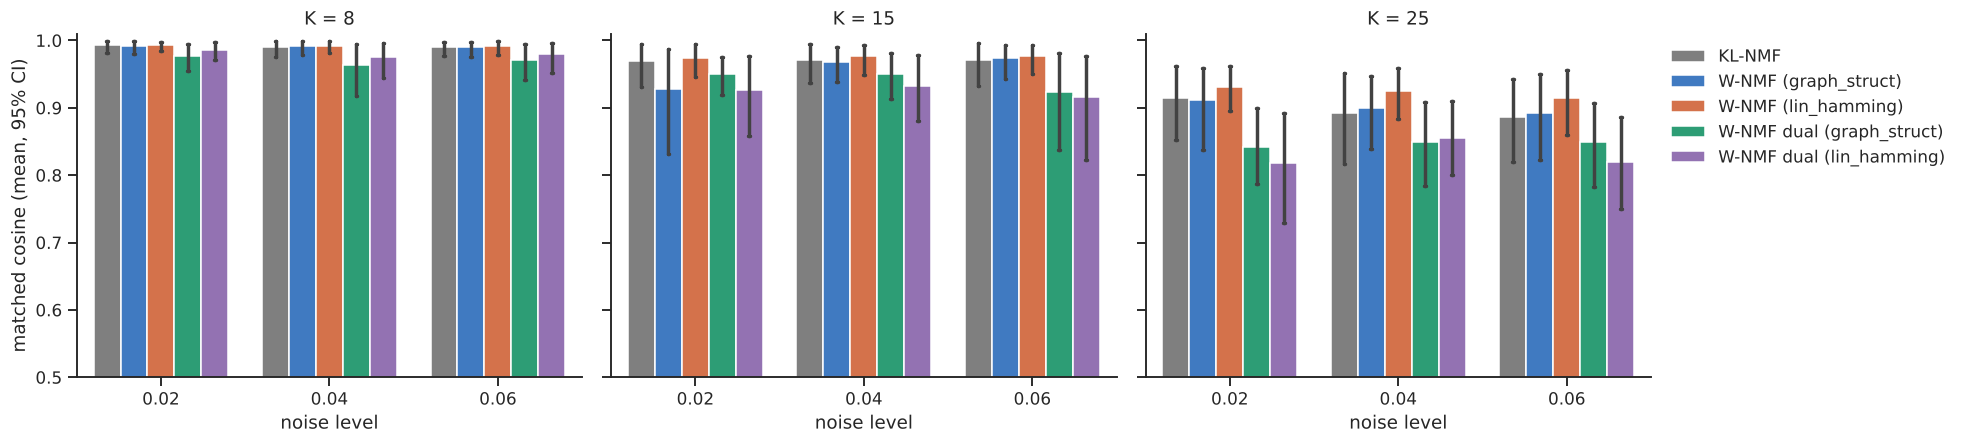

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
for ax, k in zip(axes, N_SIGNATURES_LIST):
    d = sig[sig.k == k]
    sns.barplot(data=d, x="noise", y="cosine", hue="method", palette=METHOD_COLORS, ax=ax, errorbar=("ci", 95), capsize=0.05)
    ax.set(title=f"K = {k}", ylim=(0.5, 1.01), xlabel="noise level", ylabel="matched cosine (mean, 95% CI)")
    if ax is not axes[-1]:
        ax.get_legend().remove()
axes[-1].legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

,better,worse,similar,median_diff,wilcoxon_p
method,,,,,
W-NMF (graph_struct),28,28,88,-0.0001,0.3354
W-NMF (lin_hamming),33,23,88,0.0000,0.6237
W-NMF dual (graph_struct),19,72,53,-0.0093,0.0000
W-NMF dual (lin_hamming),11,79,54,-0.0165,0.0000


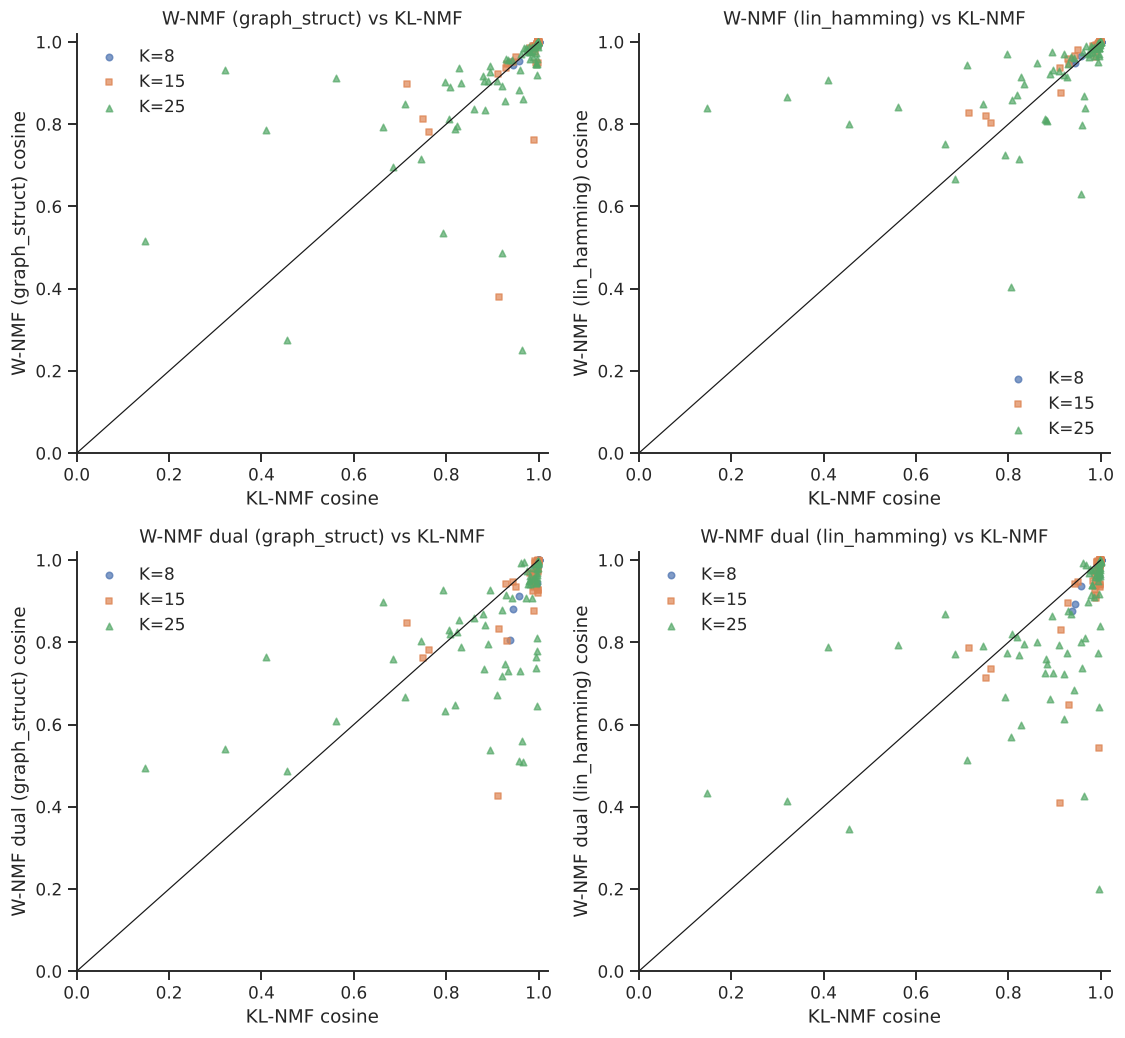

In [6]:
# Per-signature paired comparison against KL-NMF
others = [m for m in METHODS if m != "KL-NMF"]
piv = sig.pivot_table(index=["k", "noise", "signature"], columns="method", values="cosine")
ncol = min(len(others), 2)
nrow = int(np.ceil(len(others) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 4.8 * nrow), squeeze=False)
for ax in axes.flat[len(others):]:
    ax.axis("off")
tests = []
for ax, meth in zip(axes.flat, others):
    for k, mk in zip(N_SIGNATURES_LIST, ["o", "s", "^"]):
        d = piv.loc[k]
        ax.scatter(d["KL-NMF"], d[meth], s=18, marker=mk, alpha=0.7, label=f"K={k}")
    ax.plot([0, 1], [0, 1], c="k", lw=0.8)
    ax.set(xlim=(0, 1.02), ylim=(0, 1.02), xlabel="KL-NMF cosine", ylabel=f"{meth} cosine", title=f"{meth} vs KL-NMF")
    ax.legend(frameon=False)
    diff = piv[meth] - piv["KL-NMF"]
    stat = wilcoxon(piv[meth], piv["KL-NMF"])
    tests.append(dict(method=meth, better=(diff > 0.01).sum(), worse=(diff < -0.01).sum(), similar=(diff.abs() <= 0.01).sum(),
                      median_diff=diff.median(), wilcoxon_p=stat.pvalue))
plt.tight_layout()
pd.DataFrame(tests).set_index("method").round(4)

Points above the diagonal are signatures recovered better by W-NMF. "better/worse" counts signatures whose cosine differs by more than 0.01.

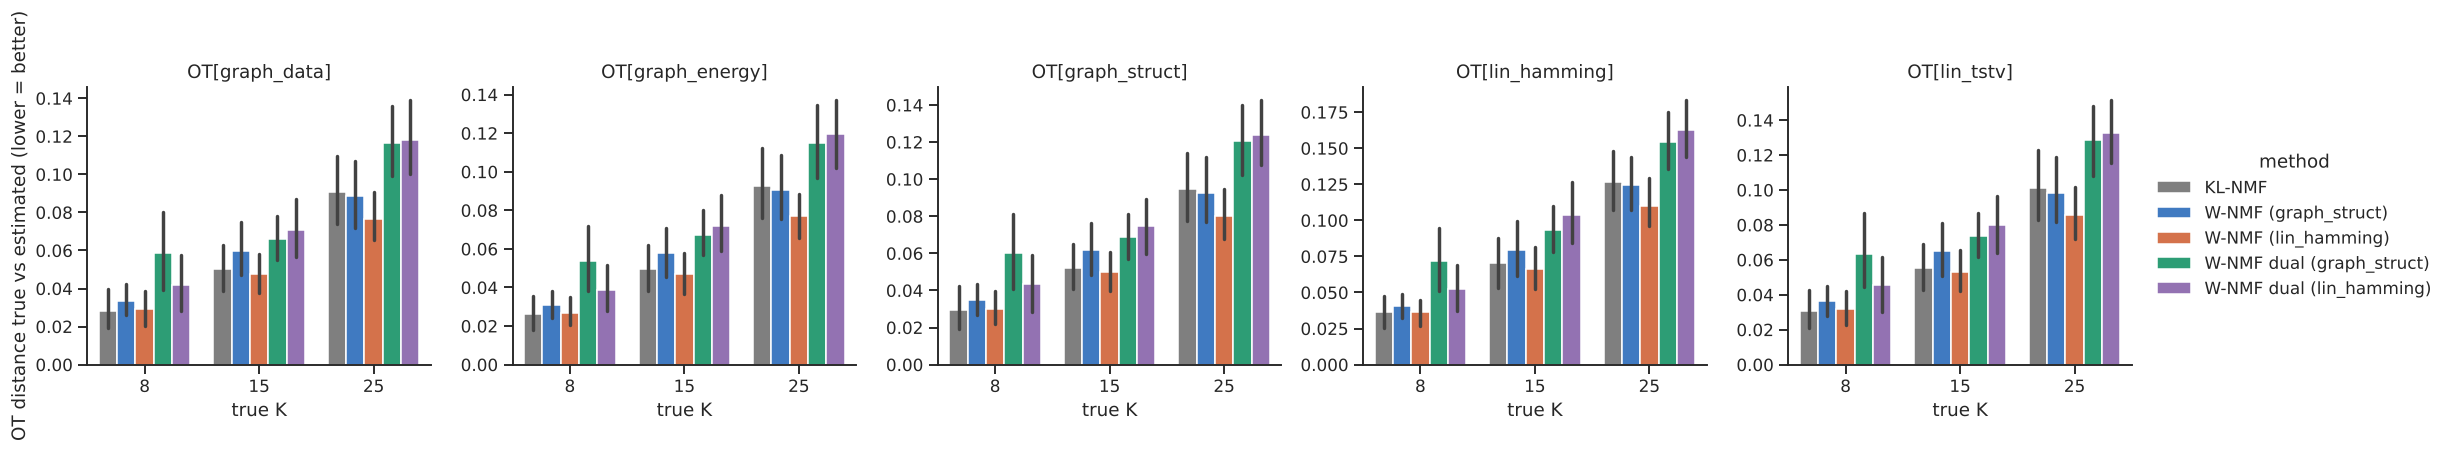

In [7]:
# OT distance between true and estimated signatures, under each scoring cost
d = sig.melt(id_vars=["method", "k", "noise", "signature"], value_vars=OT_COLS, var_name="scoring cost", value_name="OT distance")
g = sns.catplot(data=d, x="k", y="OT distance", hue="method", col="scoring cost", kind="bar", palette=METHOD_COLORS,
                errorbar=("ci", 95), height=3.6, aspect=1.1, sharey=False)
g.set_titles("{col_name}")
g.set_axis_labels("true K", "OT distance true vs estimated (lower = better)")

## 4. Exposures and the role of burden

The OT loss normalises each sample, so it could treat low- and high-burden samples differently from KL-NMF. Exposure error per sample is $\sum_s |\hat H_{sj} - H_{sj}| / \text{burden}_j$ (0 = perfect, 2 = completely wrong).

burden quintiles: {'Q1': '34-87', 'Q2': '88-167', 'Q3': '168-303', 'Q4': '304-571', 'Q5': '573-1059'}


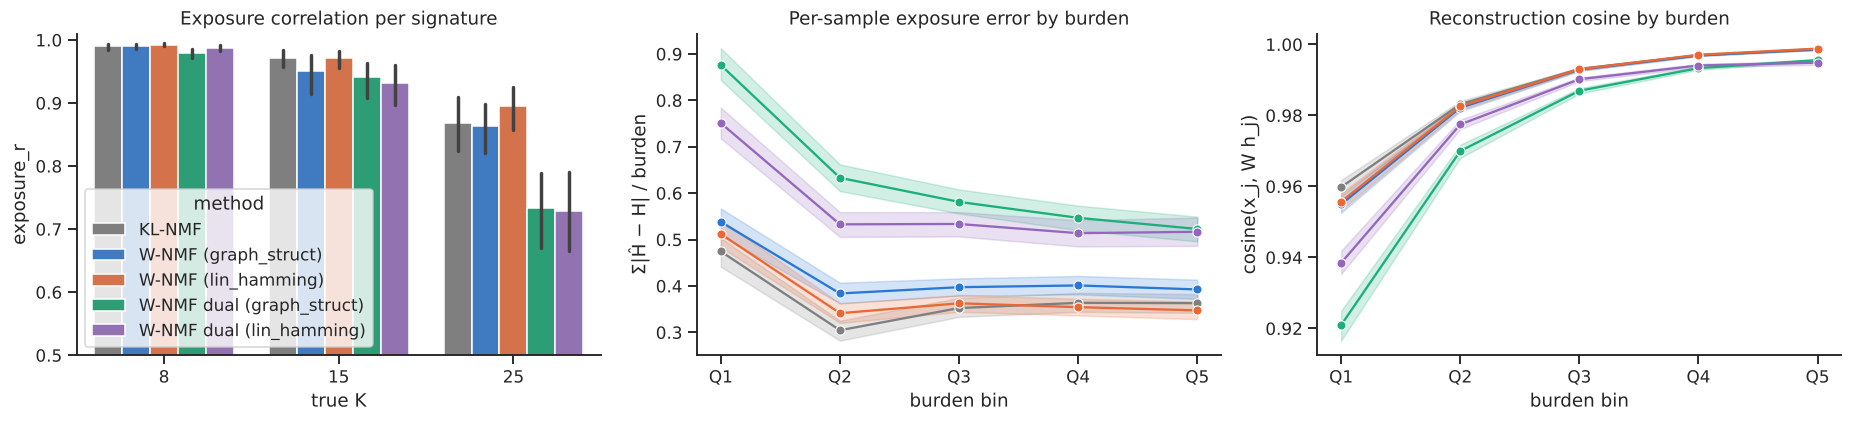

In [8]:
samp["burden bin"] = pd.qcut(samp.burden, 5, labels=[f"Q{i}" for i in range(1, 6)])
bins = samp.groupby("burden bin", observed=True).burden.agg(["min", "max"]).astype(int)
print("burden quintiles:", {b: f"{r['min']}-{r['max']}" for b, r in bins.iterrows()})

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.barplot(data=sig, x="k", y="exposure_r", hue="method", palette=METHOD_COLORS, ax=axes[0], errorbar=("ci", 95))
axes[0].set(title="Exposure correlation per signature", ylim=(0.5, 1.01), xlabel="true K")
sns.lineplot(data=samp, x="burden bin", y="exposure_err", hue="method", palette=METHOD_COLORS, ax=axes[1], marker="o", errorbar=("ci", 95))
axes[1].set(title="Per-sample exposure error by burden", ylabel="Σ|Ĥ − H| / burden")
sns.lineplot(data=samp, x="burden bin", y="recon_cosine", hue="method", palette=METHOD_COLORS, ax=axes[2], marker="o", errorbar=("ci", 95))
axes[2].set(title="Reconstruction cosine by burden", ylabel="cosine(x_j, W h_j)")
for ax in axes[1:]:
    ax.get_legend().remove()
plt.tight_layout()

## 5. Where the methods disagree

Signatures from the detailed dataset with the largest cosine difference between KL-NMF and the best-scoring W-NMF variant (by overall mean cosine): true profile (bars) with both estimates.

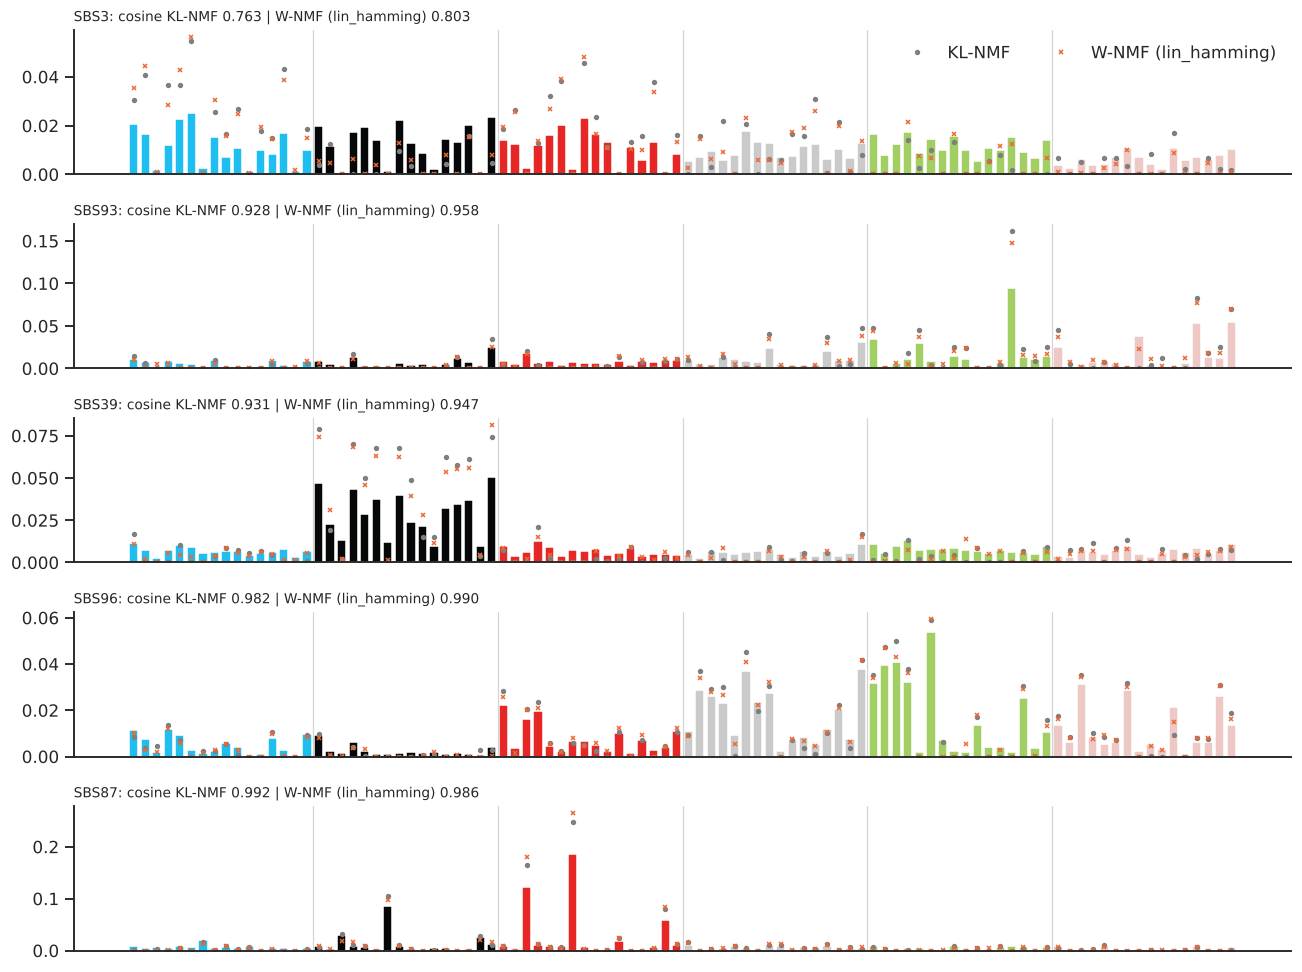

In [9]:
k, noise = DETAIL
t = tag(k, noise)
meth = overall.loc[others, "mean_cos"].idxmax()
Wt = pd.read_csv(SIM / f"W_true_{t}.csv", index_col=0).loc[CHANNELS]


def matched_W(d):
    We = pd.read_csv(d / f"W_{t}.csv", index_col=0).loc[CHANNELS]
    S = cosine_matrix(Wt.values, We.values); r, c = linear_sum_assignment(-S)
    return We.iloc[:, c].set_axis(Wt.columns[r], axis=1)[Wt.columns]

W_kl, W_w = matched_W(METHODS["KL-NMF"]), matched_W(METHODS[meth])
dd = piv.loc[(k, noise)]
show = (dd[meth] - dd["KL-NMF"]).abs().sort_values(ascending=False).index[:5]

fig, axes = plt.subplots(len(show), 1, figsize=(12, 1.8 * len(show)), sharex=True)
x = np.arange(96)
for ax, s in zip(axes, show):
    ax.bar(x, Wt[s], color=[SUB_COLORS[c] for c in SUB_OF], width=0.8)
    ax.plot(x, W_kl[s], "o", ms=2.5, c=METHOD_COLORS["KL-NMF"], label="KL-NMF")
    ax.plot(x, W_w[s], "x", ms=3, c=METHOD_COLORS[meth], label=meth)
    for i in range(1, 6):
        ax.axvline(16 * i - 0.5, c="lightgrey", lw=0.8)
    ax.set_xticks([])
    ax.set_title(f"{s}: cosine KL-NMF {dd.at[s, 'KL-NMF']:.3f} | {meth} {dd.at[s, meth]:.3f}", fontsize=9, loc="left")
axes[0].legend(frameon=False, loc="upper right", ncol=2)
plt.tight_layout()

## 6. Takeaways

The cell below prints the headline comparison from the numbers above for every Wasserstein variant against KL-NMF, then ranks all methods. Interpret it with the caveat from the top: W-NMF is scored favourably by OT metrics under its own training cost, so the neutral metrics (cosine, exposure error) carry the decision.

In [10]:
o = overall
base = o.loc["KL-NMF"]
for meth in others:
    r = o.loc[meth]
    print(f"{meth}:")
    print(f"   mean cosine {r.mean_cos:.3f} vs KL-NMF {base.mean_cos:.3f}  (Δ {r.mean_cos - base.mean_cos:+.3f})")
    print(f"   share recovered {r.recovered:.1%} vs {base.recovered:.1%}")
    print(f"   exposure r {r.exposure_r:.3f} vs {base.exposure_r:.3f};  median exposure rel. err {r.exposure_rel_err:.3f} vs {base.exposure_rel_err:.3f}")
    for c in OT_COLS:
        print(f"   {c}: {r[c]:.4f} vs {base[c]:.4f}")
    tr = pd.DataFrame(tests).set_index("method").loc[meth]
    print(f"   per-signature: better {tr.better}, worse {tr.worse}, similar {tr.similar}; Wilcoxon p = {tr.wilcoxon_p:.3g}")

print()
print("ranking by mean cosine:")
print(o.mean_cos.sort_values(ascending=False).round(3).to_string())

W-NMF (graph_struct):
   mean cosine 0.933 vs KL-NMF 0.936  (Δ -0.003)
   share recovered 81.9% vs 81.2%
   exposure r 0.912 vs 0.921;  median exposure rel. err 0.419 vs 0.337
   OT[graph_data]: 0.0703 vs 0.0678
   OT[graph_energy]: 0.0702 vs 0.0680
   OT[graph_struct]: 0.0732 vs 0.0706
   OT[lin_hamming]: 0.0965 vs 0.0940
   OT[lin_tstv]: 0.0776 vs 0.0752
   per-signature: better 28.0, worse 28.0, similar 88.0; Wilcoxon p = 0.335
W-NMF (lin_hamming):
   mean cosine 0.951 vs KL-NMF 0.936  (Δ +0.015)
   share recovered 83.3% vs 81.2%
   exposure r 0.935 vs 0.921;  median exposure rel. err 0.386 vs 0.337
   OT[graph_data]: 0.0598 vs 0.0678
   OT[graph_energy]: 0.0592 vs 0.0680
   OT[graph_struct]: 0.0624 vs 0.0706
   OT[lin_hamming]: 0.0840 vs 0.0940
   OT[lin_tstv]: 0.0665 vs 0.0752
   per-signature: better 33.0, worse 23.0, similar 88.0; Wilcoxon p = 0.624
W-NMF dual (graph_struct):
   mean cosine 0.897 vs KL-NMF 0.936  (Δ -0.039)
   share recovered 68.8% vs 81.2%
   exposure r 0.839 v